# Sound-neighbour retrieval
Audio → ASR word timing + phoneme-B → CMUdict sound neighbours. No training or API calls.

- ASR word boundaries and heard phones are both model predictions.
- Phoneme edit distance is not a calibrated probability or a confirmed pronunciation error.
- Single-word retrieval cannot reliably split a merged word or resolve homophones and names.
- Confirmed intended text is not a human annotation of the sounds actually produced.
- No human phone labels were supplied; pronunciation precision/recall cannot be measured.

In [1]:
from pathlib import Path
import json, pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd() if (Path.cwd() / 'scripts').is_dir() else Path.cwd().parent
OUT = ROOT / 'data/generated/phonetic-candidates-v1'
results = json.loads((OUT / 'results.json').read_text(encoding='utf-8'))

In [2]:
display(pd.DataFrame([{k:r[k] for k in ['file','hint','hint_source','transcript','spelling_draft','wer_vs_hint','seconds']} for r in results['records']]))

,file,hint,hint_source,transcript,spelling_draft,wer_vs_hint,seconds
0,audio-file.mp3,It was difficult to get there,user_confirmed_in_chat,It was the divicote true getesir,It was the dovecote true geter,0.666667,6.141
1,End of the road for some players.mp3,End of the road for some players,user_confirmed_in_chat,And thou theyll lo the for samun play arms,And thou theall lo the for samsung play arms,1.142857,1.219
2,Zero five eight three.mp3,Zero five eight three,user_confirmed_in_chat,Nawha it us say,Nahas it us say,1.000000,1.282


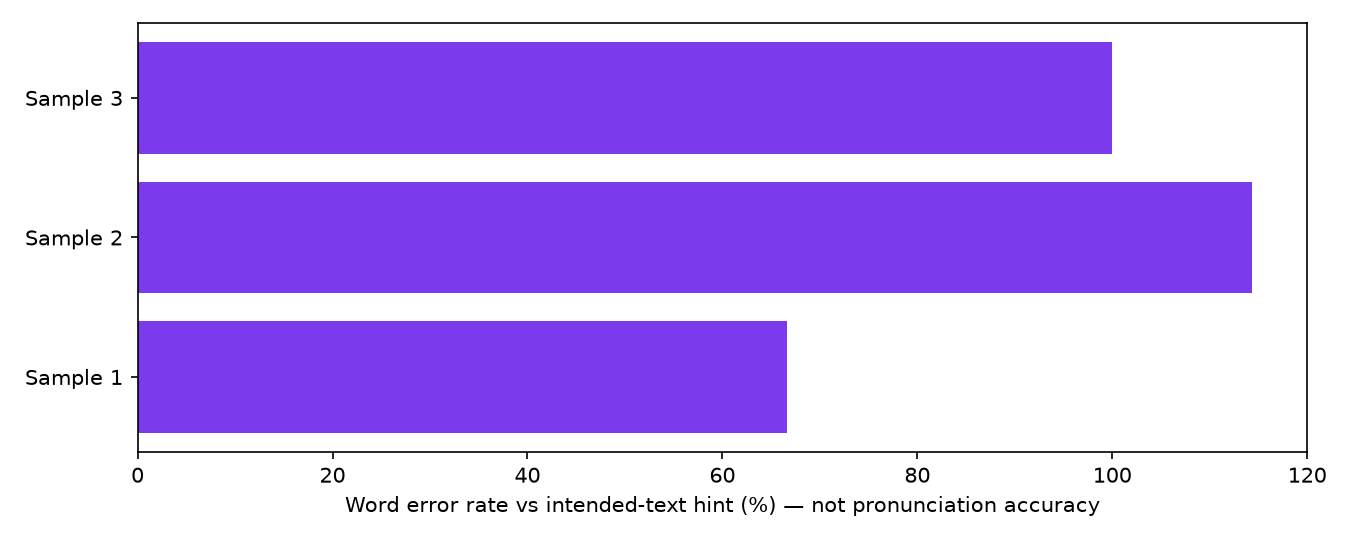

In [3]:
display(Image(filename=str(OUT / 'wer-vs-hint.png')))

In [4]:
rows = []
for record in results['records']:
    for word in record['phonetic_candidates']['words']:
        rows.append({'file':record['file'],'ASR':word['asr_word'],'predicted_phones':' '.join(word['heard_phones']),'candidates':[(c['word'],c['edit_distance']) for c in word['candidates']]})
display(pd.DataFrame(rows))

,file,ASR,predicted_phones,candidates
0,audio-file.mp3,It,IH CH,"[(itch, 0), (ich, 0), (it, 1), (bitch, 1), (di..."
1,audio-file.mp3,was,W AO Z S,"[(wachs, 1), (walks, 1), (waugh's, 1), (waltz,..."
2,audio-file.mp3,the,AH,[]
3,audio-file.mp3,divicote,D IY V IY K W T AH,[]
4,audio-file.mp3,true,T R UW,"[(true, 0), (treu, 0), (trew, 0), (trieu, 0), ..."
5,audio-file.mp3,getesir,G EH T AH S EH L,"[(gettel, 2), (gettle, 2), (gsell, 2), (carous..."
6,End of the road for some players.mp3,And,AH N,"[(an, 0), (un, 0), (and, 1), (can, 1), (ian, 1)]"
7,End of the road for some players.mp3,thou,D OW,"[(dough, 0), (dau, 0), (doe, 0), (doh, 0), (th..."
8,End of the road for some players.mp3,theyll,DH EH L,"[(they'll, 1), (hell, 1), (tell, 1), (chell, 1..."
9,End of the road for some players.mp3,lo,OW,[]


In [5]:
for record in results['records']:
    assessment = record.get('confirmed_assessment')
    if assessment:
        print(record['file'], '— intended:', record['hint'])
        display(pd.DataFrame((assessment.get('sound_candidates') or {}).get('words', [])))
        display(assessment.get('assessment'))

audio-file.mp3 — intended: It was difficult to get there


,index,text,events,tentative,start_sec,end_sec
0,0,It,"[{'kind': 'substitution', 'expected_phone': 'T...",True,0.6635,0.7440
1,1,was,"[{'kind': 'substitution', 'expected_phone': 'A...",True,0.9450,1.2466
2,2,difficult,"[{'kind': 'insertion', 'expected_phone': None,...",True,1.6689,2.2118
3,3,to,"[{'kind': 'substitution', 'expected_phone': 'T...",True,2.3525,2.5737
4,5,there,"[{'kind': 'insertion', 'expected_phone': None,...",True,2.8954,3.1970


{'method': 'ctc_variant_posterior_margin_v1',
 'status': 'ready',
 'dictionary_sha256': '81917843c7f44ce2b094ac63873c2c7a4cf802040792c455ba3ca406891c3d22',
 'checkpoint_sha256': 'da000521b31ad4d7445b8eb13d82d8a767d6535e678d727aae9baa8a8b177110',
 'vocabulary_sha256': '1ebdf682aa547489a70aa72606a3f32fa38398a12977b978b2d874dac3d6bb8d',
 'alignment': {'status': 'aligned',
  'score_eligible': True,
  'approximate_timestamps': True,
  'ctc_viterbi_log_prob': -54.374143749697396,
  'greedy_gap_per_frame': 0.2177530555303562,
  'greedy_phone_count': 25,
  'reference_phone_count': 21,
  'variant_compatible': False},
 'calibration': {'applied': False, 'reason': 'calibration_unavailable'},
 'raw_events': [{'kind': 'substitution',
   'expected_phone': 'T',
   'observed_phone': 'CH',
   'word_index': 0,
   'source': 'unvalidated_greedy_edit',
   'tentative': True},
  {'kind': 'substitution',
   'expected_phone': 'AA',
   'observed_phone': 'AO',
   'word_index': 1,
   'source': 'unvalidated_greedy_

End of the road for some players.mp3 — intended: End of the road for some players


,index,text,events,tentative,start_sec,end_sec
0,0,End,"[{'kind': 'substitution', 'expected_phone': 'E...",True,0.6617,0.8021
1,1,of,"[{'kind': 'deletion', 'expected_phone': 'AH', ...",True,0.9425,1.0829
2,2,the,"[{'kind': 'substitution', 'expected_phone': 'I...",True,1.0829,1.2433
3,3,road,"[{'kind': 'substitution', 'expected_phone': 'R...",True,1.2834,1.5441
4,4,for,"[{'kind': 'insertion', 'expected_phone': None,...",True,1.7045,2.0053
5,5,some,"[{'kind': 'substitution', 'expected_phone': 'A...",True,2.0654,2.3261
6,6,players,"[{'kind': 'insertion', 'expected_phone': None,...",True,2.6871,3.4290


{'method': 'ctc_variant_posterior_margin_v1',
 'status': 'ready',
 'dictionary_sha256': '81917843c7f44ce2b094ac63873c2c7a4cf802040792c455ba3ca406891c3d22',
 'checkpoint_sha256': 'da000521b31ad4d7445b8eb13d82d8a767d6535e678d727aae9baa8a8b177110',
 'vocabulary_sha256': '1ebdf682aa547489a70aa72606a3f32fa38398a12977b978b2d874dac3d6bb8d',
 'alignment': {'status': 'aligned',
  'score_eligible': True,
  'approximate_timestamps': True,
  'ctc_viterbi_log_prob': -80.2430194924018,
  'greedy_gap_per_frame': 0.37049510064362373,
  'greedy_phone_count': 25,
  'reference_phone_count': 21,
  'variant_compatible': False},
 'calibration': {'applied': False, 'reason': 'calibration_unavailable'},
 'raw_events': [{'kind': 'substitution',
   'expected_phone': 'EH',
   'observed_phone': 'AH',
   'word_index': 0,
   'source': 'unvalidated_greedy_edit',
   'tentative': True},
  {'kind': 'deletion',
   'expected_phone': 'AH',
   'observed_phone': None,
   'word_index': 1,
   'source': 'unvalidated_greedy_edit

Zero five eight three.mp3 — intended: Zero five eight three


,index,text,events,tentative,start_sec,end_sec
0,0,Zero,"[{'kind': 'substitution', 'expected_phone': 'Z...",True,0.6025,0.8435
1,1,five,"[{'kind': 'insertion', 'expected_phone': None,...",True,0.8636,1.1246
2,2,eight,"[{'kind': 'substitution', 'expected_phone': 'E...",True,1.4058,1.4861
3,3,three,"[{'kind': 'substitution', 'expected_phone': 'T...",True,1.5865,1.7874


{'method': 'ctc_variant_posterior_margin_v1',
 'status': 'ready',
 'dictionary_sha256': '81917843c7f44ce2b094ac63873c2c7a4cf802040792c455ba3ca406891c3d22',
 'checkpoint_sha256': 'da000521b31ad4d7445b8eb13d82d8a767d6535e678d727aae9baa8a8b177110',
 'vocabulary_sha256': '1ebdf682aa547489a70aa72606a3f32fa38398a12977b978b2d874dac3d6bb8d',
 'alignment': {'status': 'aligned',
  'score_eligible': True,
  'approximate_timestamps': True,
  'ctc_viterbi_log_prob': -71.84448828361928,
  'greedy_gap_per_frame': 0.4632152860199124,
  'greedy_phone_count': 14,
  'reference_phone_count': 12,
  'variant_compatible': False},
 'calibration': {'applied': False, 'reason': 'calibration_unavailable'},
 'raw_events': [{'kind': 'substitution',
   'expected_phone': 'Z',
   'observed_phone': 'D',
   'word_index': 0,
   'source': 'unvalidated_greedy_edit',
   'tentative': True},
  {'kind': 'substitution',
   'expected_phone': 'IH',
   'observed_phone': 'EH',
   'word_index': 0,
   'source': 'unvalidated_greedy_ed

In [6]:
display(results['protocol'])

{'inputs': [{'file': 'audio-file.mp3',
   'sha256': '44de4765d126b6f1787aec57465d85e8352739ee7f02a924700d13606d1d0b98',
   'hint': 'It was difficult to get there',
   'hint_source': 'user_confirmed_in_chat'},
  {'file': 'End of the road for some players.mp3',
   'sha256': '86d89d85c120146dd8c59ab1d9aded910a375c231d7a422e18c8fa618eb24efb',
   'hint': 'End of the road for some players',
   'hint_source': 'user_confirmed_in_chat'},
  {'file': 'Zero five eight three.mp3',
   'sha256': 'fd7c8ce0a19f2f24d5203028f902d874a7854409ea2513f46c244e19ac63f1be',
   'hint': 'Zero five eight three',
   'hint_source': 'user_confirmed_in_chat'}],
 'inference': 'local CPU only',
 'models': 'wav2vec2-base-960h and frozen phoneme-B',
 'code_sha256': 'a14859866dcd80fe638a24d7e4c4e23912a07aafb86a9297fc7a0f3e0ce3c41c',
 'hints_used_in_recognition_or_retrieval': False,
 'training': False,
 'external_api_calls': 0,
 'limitations': ['ASR word boundaries and heard phones are both model predictions.',
  'Phoneme ed